# `vkcolorcet` Demo — Perceptually Uniform Vulkan GPU Colormaps

Drop-in `colorcet`-style colormaps (`fire`, `bmy`, `bgy`, `kbc`, `viridis`, `inferno`, `plasma`, `magma`, `turbo`, `coolwarm`, `rainbow`, `glasbey`, ...) executed directly inside `vkshader`'s zero-copy Vulkan SPIR-V LUT shader!

In [3]:
import sys
from pathlib import Path
_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import vkcolorcet as cc
cc.swatches()

fire,
bmy,
bgy,
bgyw,
kbc,
kb,
kg,
kr,
bmw,
viridis,
inferno,


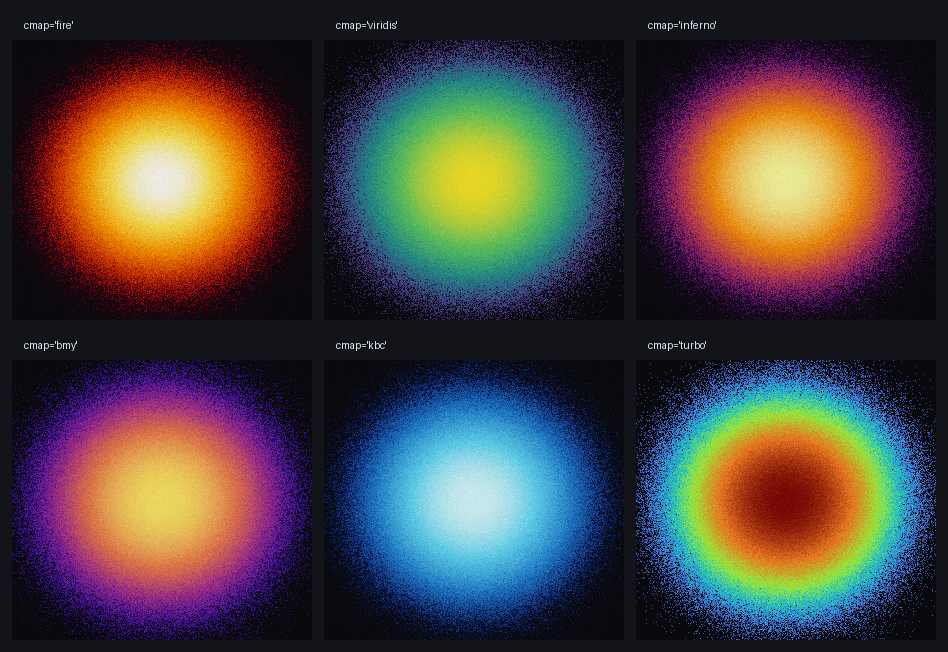

In [4]:
import numpy as np
import vknumpy as vnp
import vkpandas as vpd
import vkholoviews as hv
import vkplot.vkpandas  # noqa: F401

# Render 2M GPU points with 6 different vkcolorcet colormaps
rng = np.random.default_rng(77)
n = 2_000_000
df = vpd.DataFrame({
    "x": vnp.array(rng.normal(0.0, 1.0, size=n).astype(np.float32)),
    "y": vnp.array(rng.normal(0.0, 1.0, size=n).astype(np.float32)),
})

cmaps = ["fire", "viridis", "inferno", "bmy", "kbc", "turbo"]
plots = [
    df.vkplot.points("x", "y", cmap=cm, width=300, height=280, xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), title=f"cmap={cm!r}")
    for cm in cmaps
]
hv.Layout(plots).cols(3)

## All `vkcolorcet` Colormaps Rendered on Vulkan GPU (2M Points)

Rendered all 26 colormaps on 2M GPU points in 54.8 ms


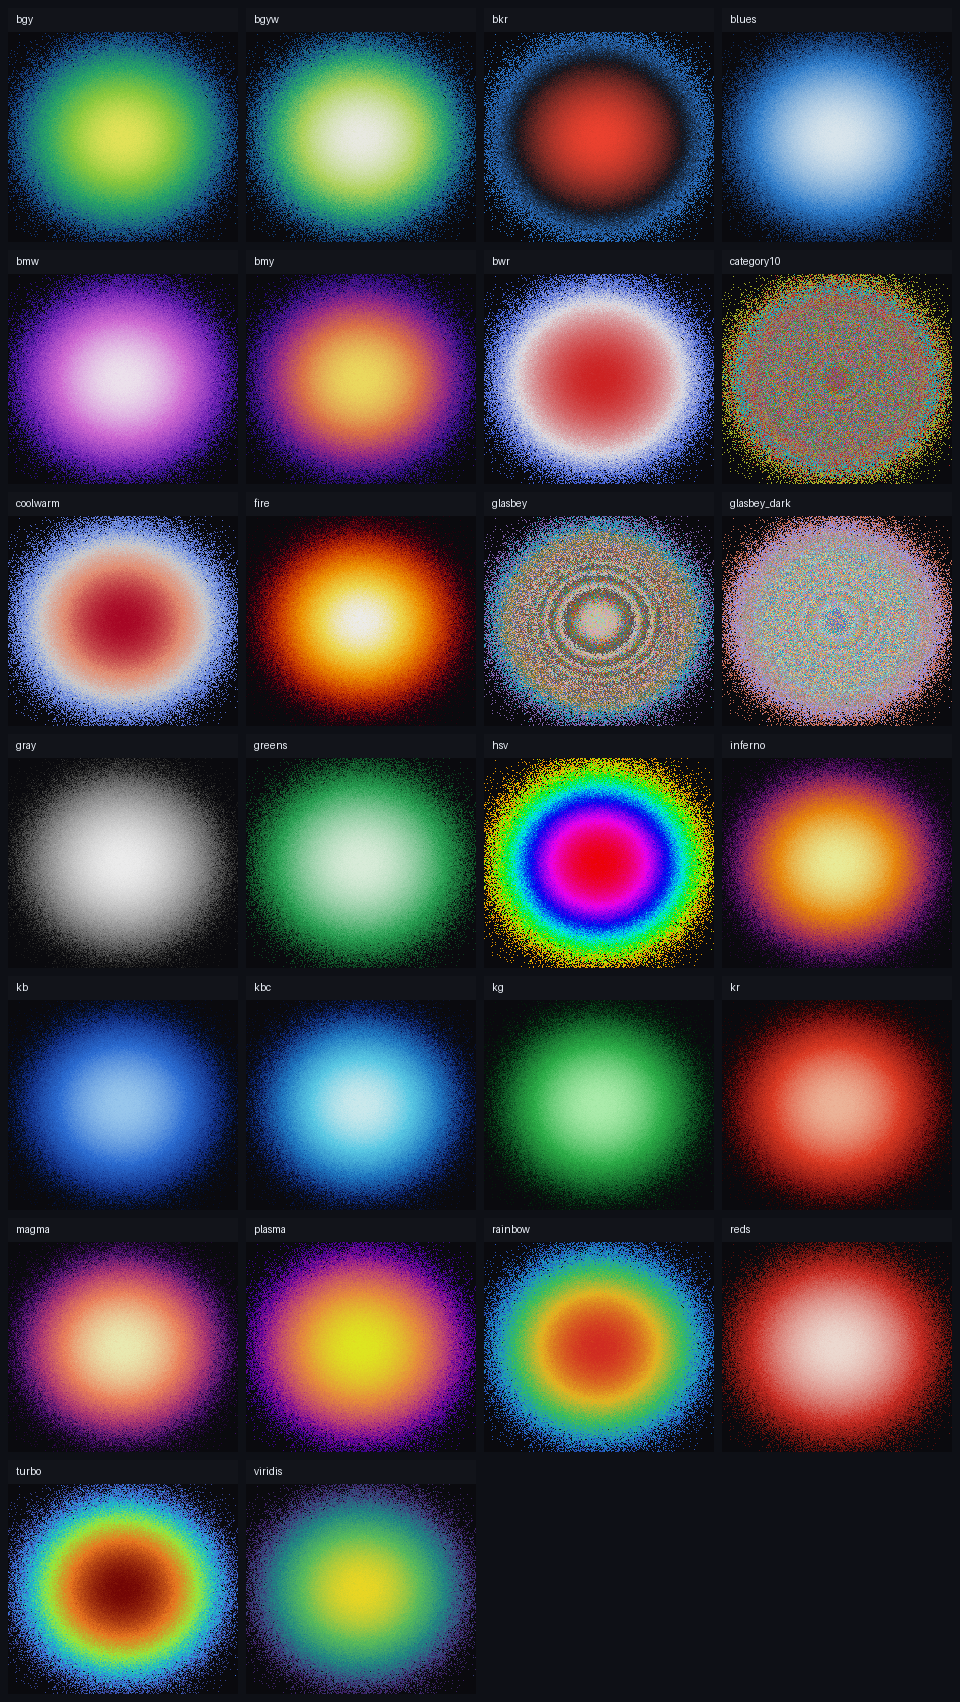

In [5]:
import time
import vkshader as vks
from PIL import Image, ImageDraw

# Every primary colormap in vkcolorcet (sequential, diverging, cyclic, categorical)
all_cmaps = [k for k in sorted(cc.palette.keys()) if not k.endswith("_r")]

# Rasterize 2M points ONCE on GPU, then shade all colormaps via zero-copy GPU LUT!
t0 = time.perf_counter()
w, h = 230, 210
cvs = vks.Canvas(w, h, x_range=(-3.5, 3.5), y_range=(-3.5, 3.5))
agg = cvs.points(df, "x", "y")
tiles = []
for cm in all_cmaps:
    im = vks.shade(agg, how="eq_hist", cmap=cm, basemap=None, spread_px=0).to_pil()
    tile = Image.new("RGBA", (w, h + 24), (18, 20, 26, 255))
    ImageDraw.Draw(tile).text((8, 5), cm, fill=(235, 240, 248, 255))
    tile.paste(im, (0, 24))
    tiles.append(tile)
elapsed_ms = (time.perf_counter() - t0) * 1000.0
print(f"Rendered all {len(all_cmaps)} colormaps on 2M GPU points in {elapsed_ms:.1f} ms")

cols = 4
rows = (len(tiles) + cols - 1) // cols
pad = 8
grid = Image.new("RGBA", (cols * (w + pad) + pad, rows * (h + 24 + pad) + pad), (14, 16, 22, 255))
for idx, tile in enumerate(tiles):
    r, c = divmod(idx, cols)
    grid.paste(tile, (pad + c * (w + pad), pad + r * (h + 24 + pad)))
grid